<a href="https://colab.research.google.com/github/Reina-creator/MSSP607-GitHub/blob/main/Assignment/Assignment02_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path
from IPython.display import display

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

owner = "Reina-creator"
repository = "MSSP607-GitHub"
repo_url = f"https://github.com/{owner}/{repository}.git"
repo_path = Path("/content") / repository

if not repo_path.exists():
    subprocess.run(
        ["git", "clone", repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob("*")):
    if item.is_file() and ".git" not in item.parts:
        print(item.relative_to(repo_path))

Current directory: /content/MSSP607-GitHub
Files in repository:
Adding_File_Structure.py
Assignment/Assignment 01
Assignment/Assignment1_Academic_Performance.ipynb
Assignment_template.ipynb
README.md
WeeklyModule/Week02/Week_2_assignment.ipynb
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week03AssignmentsWeek3_Assignment.ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Ruizhu_Zuo_Week4_Pandas_Assignment.ipynb.ipynb
WeeklyModules/Week05/.gitkeep
WeeklyModules/Week05/Week5_Assignment.ipynb
WeeklyModules/Week06/.gitkeep
WeeklyModules/Week06/Week06_assignment.ipynb
WeeklyModules/Week07/.gitkeep
WeeklyModules/Week07/Week7Assignment.ipynb
WeeklyModules/Week08/.gitkeep
WeeklyModules/Week08/Assignment8.ipynb
WeeklyModules/Week08/Week 08 Time and Date.ipynb
WeeklyModules/Week09/.gitkeep
WeeklyModules/Week10/.gitkeep
WeeklyModules/Week11/.gitkeep
WeeklyModules/Week12/.gitkeep
WeeklyModules/Week13/.gi

In [2]:
data_file = repo_path / "data" / "InternetSales.csv"

sales = pd.read_csv(
    data_file,
    encoding="latin1",
    low_memory=False
)

sns.set_theme(style="whitegrid")

print("Rows:", len(sales))
print("Columns:", sales.shape[1])

display(sales.head())

Rows: 60398
Columns: 60


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,8.22,21.98,1.76,0.55,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,10.84,28.99,2.32,0.72,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [3]:
required_columns = [
    "CustomerKey",
    "EnglishCountryRegionName",
    "Gender",
    "YearlyIncome",
    "HouseOwnerFlag",
    "EnglishProductName",
    "OrderDate",
    "SalesOrderNumber",
    "SalesOrderLineNumber",
    "OrderQuantity",
    "SalesAmount"
]

missing_columns = set(required_columns) - set(sales.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

sales["OrderDate"] = pd.to_datetime(
    sales["OrderDate"],
    format="%m/%d/%Y",
    errors="raise"
)

sales["Year"] = sales["OrderDate"].dt.year

print("Missing values in analysis columns:")
display(sales[required_columns].isna().sum().to_frame("Missing values"))

print(
    "Duplicate order lines:",
    sales.duplicated(
        subset=["SalesOrderNumber", "SalesOrderLineNumber"]
    ).sum()
)

print("Earliest order:", sales["OrderDate"].min().date())
print("Latest order:", sales["OrderDate"].max().date())

# Confirm that customer attributes are consistent across purchases.
customer_attributes = [
    "EnglishCountryRegionName",
    "Gender",
    "YearlyIncome",
    "HouseOwnerFlag"
]

attribute_consistency = (
    sales.groupby("CustomerKey")[customer_attributes]
    .nunique(dropna=False)
    .max()
)

print("\nMaximum distinct values per customer:")
display(attribute_consistency.to_frame("Maximum distinct values"))

# Each row represents one product line within an order.

Missing values in analysis columns:


,Missing values
CustomerKey,0
EnglishCountryRegionName,0
Gender,0
YearlyIncome,0
HouseOwnerFlag,0
EnglishProductName,0
OrderDate,0
SalesOrderNumber,0
SalesOrderLineNumber,0
OrderQuantity,0


Duplicate order lines: 0
Earliest order: 2010-12-29
Latest order: 2014-01-28

Maximum distinct values per customer:


,Maximum distinct values
EnglishCountryRegionName,1
Gender,1
YearlyIncome,1
HouseOwnerFlag,1


In [4]:
annual_summary = (
    sales.groupby("Year")
    .agg(
        TotalSales=("SalesAmount", "sum"),
        UnitsSold=("OrderQuantity", "sum"),
        Orders=("SalesOrderNumber", "nunique"),
        Customers=("CustomerKey", "nunique"),
        FirstOrder=("OrderDate", "min"),
        LastOrder=("OrderDate", "max")
    )
)

annual_summary["Coverage"] = [
    "Partial year" if year in [2010, 2014] else "Full calendar year"
    for year in annual_summary.index
]

annual_summary["AverageOrderValue"] = (
    annual_summary["TotalSales"] / annual_summary["Orders"]
)

display(annual_summary)

# Use full calendar years for comparable business analysis.
analysis_sales = sales[
    sales["Year"].between(2011, 2013)
].copy()

full_year_summary = annual_summary.loc[2011:2013].copy()

full_year_summary["SalesGrowthPct"] = (
    full_year_summary["TotalSales"].pct_change() * 100
)

display(full_year_summary)

,TotalSales,UnitsSold,Orders,Customers,FirstOrder,LastOrder,Coverage,AverageOrderValue
Year,,,,,,,,
2010,43421.04,14,14,14,2010-12-29,2010-12-31,Partial year,3101.50
2011,7075525.93,2216,2216,2216,2011-01-01,2011-12-31,Full calendar year,3192.93
2012,5842485.20,3397,3269,3255,2012-01-01,2012-12-31,Full calendar year,1787.24
2013,16351550.34,52801,21289,17429,2013-01-01,2013-12-31,Full calendar year,768.08
2014,45694.72,1970,871,834,2014-01-01,2014-01-28,Partial year,52.46


,TotalSales,UnitsSold,Orders,Customers,FirstOrder,LastOrder,Coverage,AverageOrderValue,SalesGrowthPct
Year,,,,,,,,,
2011,7075525.93,2216,2216,2216,2011-01-01,2011-12-31,Full calendar year,3192.93,NaN
2012,5842485.20,3397,3269,3255,2012-01-01,2012-12-31,Full calendar year,1787.24,-17.43
2013,16351550.34,52801,21289,17429,2013-01-01,2013-12-31,Full calendar year,768.08,179.87


Question 1

In [5]:
country_year_sales = sales.pivot_table(
    index="EnglishCountryRegionName",
    columns="Year",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

print("Sales by country and year, including partial years:")
display(country_year_sales)

print("Note: 2010 and 2014 contain partial-year data.")

country_year_full = country_year_sales.loc[:, [2011, 2012, 2013]]

country_growth = (
    country_year_full.pct_change(axis=1) * 100
).loc[:, [2012, 2013]]

country_growth.columns = [
    "Growth_2012_Pct",
    "Growth_2013_Pct"
]

print("\nYear-over-year growth using full calendar years:")
display(country_growth)

country_summary = (
    analysis_sales.groupby("EnglishCountryRegionName")
    .agg(
        TotalSales=("SalesAmount", "sum"),
        Orders=("SalesOrderNumber", "nunique"),
        Customers=("CustomerKey", "nunique")
    )
    .sort_values("TotalSales", ascending=False)
)

country_summary["SalesSharePct"] = (
    country_summary["TotalSales"]
    / country_summary["TotalSales"].sum()
    * 100
)

country_summary["SalesPerCustomer"] = (
    country_summary["TotalSales"]
    / country_summary["Customers"]
)

country_summary["AverageOrderValue"] = (
    country_summary["TotalSales"]
    / country_summary["Orders"]
)

display(country_summary)

Sales by country and year, including partial years:


Year,2010,2011,2012,2013,2014
EnglishCountryRegionName,,,,,
Australia,20909.78,2563732.25,2128407.46,4339443.38,8507.72
Canada,3578.27,571571.80,307604.52,1085632.65,9457.62
France,3399.99,410845.33,648065.54,1578511.80,3195.06
Germany,0.00,520500.16,608657.98,1761876.36,3277.83
United Kingdom,699.10,550591.22,712700.96,2124007.29,3713.64
United States,14833.90,2458285.17,1437048.73,5462078.86,17542.85


Note: 2010 and 2014 contain partial-year data.

Year-over-year growth using full calendar years:


,Growth_2012_Pct,Growth_2013_Pct
EnglishCountryRegionName,,
Australia,-16.98,103.88
Canada,-46.18,252.93
France,57.74,143.57
Germany,16.94,189.47
United Kingdom,29.44,198.02
United States,-41.54,280.09


,TotalSales,Orders,Customers,SalesSharePct,SalesPerCustomer,AverageOrderValue
EnglishCountryRegionName,,,,,,
United States,9357412.76,9227,7549,31.97,1239.56,1014.13
Australia,9031583.08,6556,3543,30.86,2549.13,1377.61
United Kingdom,3387299.47,2957,1874,11.57,1807.52,1145.52
Germany,2891034.51,2423,1720,9.88,1680.83,1193.16
France,2637422.66,2416,1746,9.01,1510.55,1091.65
Canada,1964808.97,3195,1545,6.71,1271.72,614.96


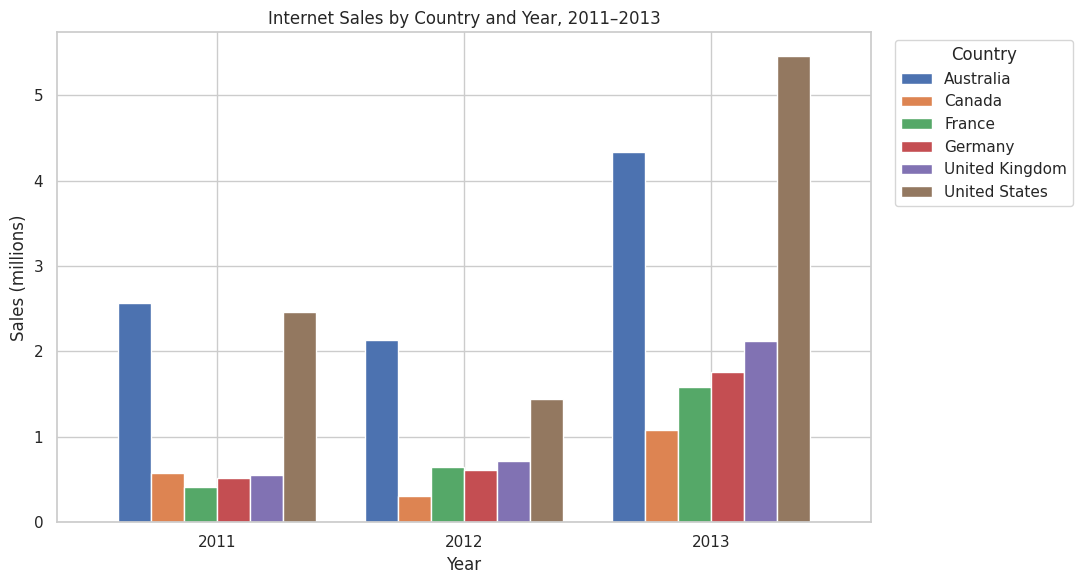

In [6]:
ax = (country_year_full.T / 1_000_000).plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Internet Sales by Country and Year, 2011–2013")
ax.set_xlabel("Year")
ax.set_ylabel("Sales (millions)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

Question 2

In [7]:
# All unique customers for demographic summary statistics.
all_customers = (
    sales[["CustomerKey"] + customer_attributes]
    .drop_duplicates(subset="CustomerKey")
    .copy()
)

# Customers observed during the common spending analysis period.
customers = (
    analysis_sales[["CustomerKey"] + customer_attributes]
    .drop_duplicates(subset="CustomerKey")
    .copy()
)

print("Unique customers in the complete dataset:", len(all_customers))
print("Unique customers in 2011–2013:", len(customers))

income_by_country = (
    all_customers.groupby("EnglishCountryRegionName")
    .agg(
        Customers=("CustomerKey", "nunique"),
        IncomeMean=("YearlyIncome", "mean"),
        IncomeMedian=("YearlyIncome", "median"),
        IncomeMin=("YearlyIncome", "min"),
        IncomeMax=("YearlyIncome", "max"),
        IncomeStd=("YearlyIncome", "std")
    )
)

print("\nIncome statistics by country:")
display(income_by_country)

income_by_country_gender = (
    all_customers.groupby(["EnglishCountryRegionName", "Gender"])
    .agg(
        Customers=("CustomerKey", "nunique"),
        IncomeMean=("YearlyIncome", "mean"),
        IncomeMedian=("YearlyIncome", "median"),
        IncomeMin=("YearlyIncome", "min"),
        IncomeMax=("YearlyIncome", "max"),
        IncomeStd=("YearlyIncome", "std")
    )
)

print("\nIncome statistics by country and gender:")
display(income_by_country_gender)

gender_counts = pd.crosstab(
    all_customers["EnglishCountryRegionName"],
    all_customers["Gender"]
).reindex(columns=["F", "M"], fill_value=0)

gender_percentages = (
    gender_counts.div(gender_counts.sum(axis=1), axis=0) * 100
)

gender_summary = pd.concat(
    [
        gender_counts.rename(
            columns={"F": "FemaleCustomers", "M": "MaleCustomers"}
        ),
        gender_percentages.rename(
            columns={"F": "FemalePct", "M": "MalePct"}
        )
    ],
    axis=1
)

print("\nGender counts and percentages by country:")
display(gender_summary)

Unique customers in the complete dataset: 18484
Unique customers in 2011–2013: 17977

Income statistics by country:


,Customers,IncomeMean,IncomeMedian,IncomeMin,IncomeMax,IncomeStd
EnglishCountryRegionName,,,,,,
Australia,3591,64338.62,70000.00,10000,170000,31830.00
Canada,1571,57167.41,60000.00,10000,170000,20251.52
France,1810,35762.43,30000.00,10000,110000,27277.40
Germany,1780,42943.82,30000.00,10000,130000,35493.58
United Kingdom,1913,52169.37,30000.00,10000,170000,48431.99
United States,7819,63616.83,60000.00,10000,170000,25706.48



Income statistics by country and gender:


Customers  IncomeMean  IncomeMedian  \
EnglishCountryRegionName Gender                                        
Australia                F            1777    65284.19      70000.00   
                         M            1814    63412.35      70000.00   
Canada                   F             767    56505.87      60000.00   
                         M             804    57798.51      60000.00   
France                   F             893    35341.55      30000.00   
                         M             917    36172.30      30000.00   
Germany                  F             874    43810.07      30000.00   
                         M             906    42108.17      30000.00   
United Kingdom           F             934    52184.15      30000.00   
                         M             979    52155.26      30000.00   
United States            F            3888    63276.75      60000.00   
                         M            3931    63953.19      60000.00   

                                 IncomeMin  IncomeMax  IncomeStd  
EnglishCountryRegionName Gender                                   
Australia                F           10000     160000   31164.36  
                         M           10000     170000   32450.71  
Canada                   F           10000     170000   19181.55  
                         M           10000     170000   21214.77  
France                   F           10000     110000   26915.85  
                         M           10000     110000   27633.45  
Germany                  F           10000     130000   35715.76  
                         M           10000     130000   35277.49  
United Kingdom           F           10000     170000   48288.44  
                         M           10000     170000   48593.22  
United States            F           10000     170000   25166.56  
                         M           10000     170000   26228.43


Gender counts and percentages by country:


Gender,FemaleCustomers,MaleCustomers,FemalePct,MalePct
EnglishCountryRegionName,,,,
Australia,1777,1814,49.48,50.52
Canada,767,804,48.82,51.18
France,893,917,49.34,50.66
Germany,874,906,49.10,50.90
United Kingdom,934,979,48.82,51.18
United States,3888,3931,49.73,50.27


In [8]:
def classify_product(product_name):
    if product_name.startswith("Mountain-"):
        return "Bikes", "Mountain Bikes"

    if product_name.startswith("Road-"):
        return "Bikes", "Road Bikes"

    if product_name.startswith("Touring-"):
        return "Bikes", "Touring Bikes"

    clothing_rules = [
        ("Cap", "Caps"),
        ("Gloves", "Gloves"),
        ("Jersey", "Jerseys"),
        ("Shorts", "Shorts"),
        ("Socks", "Socks"),
        ("Vest", "Vests")
    ]

    for keyword, subcategory in clothing_rules:
        if keyword in product_name:
            return "Clothing", subcategory

    accessory_rules = [
        ("Helmet", "Helmets"),
        ("Bottle Cage", "Bottle Cages"),
        ("Water Bottle", "Water Bottles"),
        ("Tire Tube", "Tires and Tubes"),
        ("Tire", "Tires and Tubes"),
        ("Bike Stand", "Bike Stands"),
        ("Bike Wash", "Bike Wash"),
        ("Fender", "Fenders"),
        ("Hitch Rack", "Bike Racks"),
        ("Hydration Pack", "Hydration Packs"),
        ("Patch Kit", "Repair Kits")
    ]

    for keyword, subcategory in accessory_rules:
        if keyword in product_name:
            return "Accessories", subcategory

    return "Unclassified", "Unclassified"


product_lookup = (
    sales[["EnglishProductName"]]
    .drop_duplicates()
    .sort_values("EnglishProductName")
    .reset_index(drop=True)
)

product_lookup[["ProductCategory", "ProductSubcategory"]] = pd.DataFrame(
    product_lookup["EnglishProductName"]
    .apply(classify_product)
    .tolist(),
    index=product_lookup.index
)

if product_lookup["ProductCategory"].eq("Unclassified").any():
    display(
        product_lookup[
            product_lookup["ProductCategory"].eq("Unclassified")
        ]
    )
    raise ValueError("Some products need a category.")

sales = (
    sales.drop(
        columns=["ProductCategory", "ProductSubcategory"],
        errors="ignore"
    )
    .merge(
        product_lookup,
        on="EnglishProductName",
        how="left",
        validate="many_to_one"
    )
)

analysis_sales = sales[
    sales["Year"].between(2011, 2013)
].copy()

print("Product classification based on product names:")
display(product_lookup)

Product classification based on product names:


,EnglishProductName,ProductCategory,ProductSubcategory
0,AWC Logo Cap,Clothing,Caps
1,All-Purpose Bike Stand,Accessories,Bike Stands
2,Bike Wash - Dissolver,Accessories,Bike Wash
3,"Classic Vest, L",Clothing,Vests
4,"Classic Vest, M",Clothing,Vests
...,...,...,...
125,"Touring-3000 Yellow, 62",Bikes,Touring Bikes
126,Water Bottle - 30 oz.,Accessories,Water Bottles
127,"Women's Mountain Shorts, L",Clothing,Shorts
128,"Women's Mountain Shorts, M",Clothing,Shorts


Question 3

In [9]:
category_year_sales = sales.pivot_table(
    index="ProductCategory",
    columns="Year",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

print("Category sales by year; 2010 and 2014 are partial years:")
display(category_year_sales)

category_summary = (
    analysis_sales.groupby("ProductCategory")
    .agg(
        TotalSales=("SalesAmount", "sum"),
        UnitsSold=("OrderQuantity", "sum"),
        Orders=("SalesOrderNumber", "nunique")
    )
    .sort_values("TotalSales", ascending=False)
)

category_summary["SalesSharePct"] = (
    category_summary["TotalSales"]
    / category_summary["TotalSales"].sum()
    * 100
)

# Revenue-weighted by units: actual revenue per unit sold.
category_summary["AverageSellingPrice"] = (
    category_summary["TotalSales"]
    / category_summary["UnitsSold"]
)

display(category_summary)

top_category = category_summary.index[0]
top_category_price = category_summary.loc[
    top_category, "AverageSellingPrice"
]

print("Category generating the most sales revenue:", top_category)
print(f"Average selling price: {top_category_price:,.2f}")

subcategory_summary = (
    analysis_sales.groupby(["ProductCategory", "ProductSubcategory"])
    .agg(
        TotalSales=("SalesAmount", "sum"),
        UnitsSold=("OrderQuantity", "sum")
    )
    .sort_values("TotalSales", ascending=False)
)

subcategory_summary["AverageSellingPrice"] = (
    subcategory_summary["TotalSales"]
    / subcategory_summary["UnitsSold"]
)

print("\nSubcategory results:")
display(subcategory_summary)

Category sales by year; 2010 and 2014 are partial years:


Year,2010,2011,2012,2013,2014
ProductCategory,,,,,
Accessories,0.00,0.00,2147.08,668241.53,30371.35
Bikes,43421.04,7075525.93,5839695.33,15359502.36,0.00
Clothing,0.00,0.00,642.79,323806.45,15323.37


,TotalSales,UnitsSold,Orders,SalesSharePct,AverageSellingPrice
ProductCategory,,,,,
Bikes,28274723.61,15191,15191,96.60,1861.28
Accessories,670388.61,34515,17434,2.29,19.42
Clothing,324449.24,8708,7145,1.11,37.26


Category generating the most sales revenue: Bikes
Average selling price: 1,861.28

Subcategory results:


TotalSales  UnitsSold  AverageSellingPrice
ProductCategory ProductSubcategory                                            
Bikes           Road Bikes         14494137.95       8059              1798.50
                Mountain Bikes      9935784.61       4965              2001.17
                Touring Bikes       3844801.05       2167              1774.25
Accessories     Tires and Tubes      225915.56      13377                16.89
                Helmets              216938.00       6200                34.99
Clothing        Jerseys              165990.03       3197                51.92
                Shorts                67400.37        963                69.99
Accessories     Fenders               44553.46       2027                21.98
                Hydration Packs       39042.90        710                54.99
                Bike Stands           37842.00        238               159.00
                Bike Racks            36960.00        308               120.00
                Bottle Cages          34840.42       3658                 9.52
Clothing        Vests                 33782.00        532                63.50
                Gloves                33453.34       1366                24.49
Accessories     Water Bottles         20449.02       4098                 4.99
Clothing        Caps                  18941.93       2107                 8.99
Accessories     Repair Kits            6938.70       3030                 2.29
                Bike Wash              6908.55        869                 7.95
Clothing        Socks                  4881.57        543                 8.99

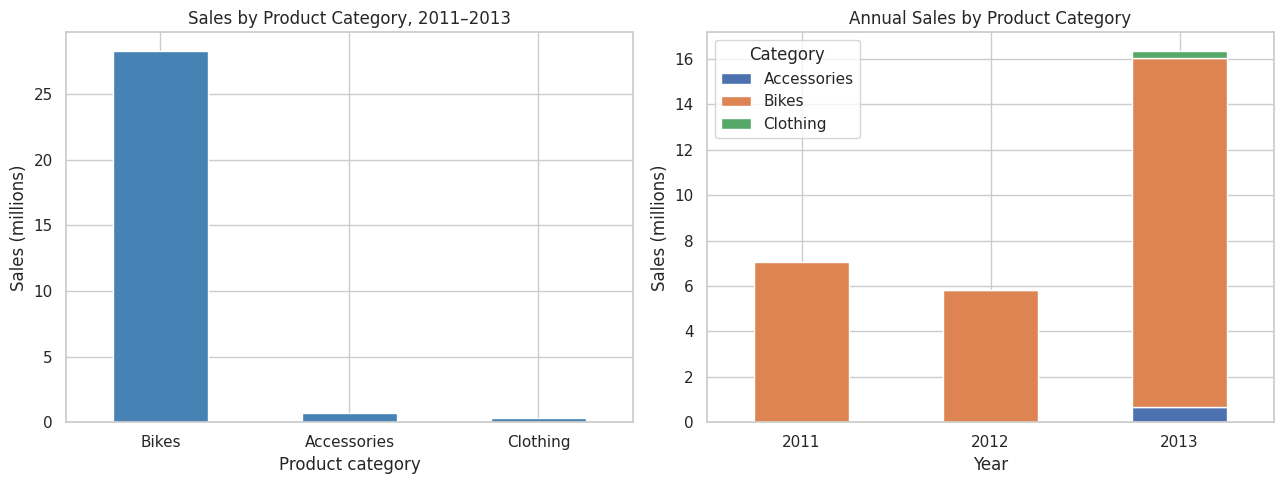

Country and category sales, 2011–2013:


ProductCategory,Accessories,Bikes,Clothing
EnglishCountryRegionName,,,
Australia,133337.20,8831140.22,67105.66
Canada,96979.01,1817724.12,50105.84
France,61041.93,2550175.72,26205.01
Germany,59748.56,2808514.35,22771.60
United Kingdom,74246.09,3282143.56,30909.82
United States,245035.82,8985025.63,127351.31


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

category_summary["TotalSales"].div(1_000_000).plot(
    kind="bar",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Sales by Product Category, 2011–2013")
axes[0].set_xlabel("Product category")
axes[0].set_ylabel("Sales (millions)")
axes[0].tick_params(axis="x", rotation=0)

category_year_sales.loc[:, [2011, 2012, 2013]].T.div(1_000_000).plot(
    kind="bar",
    stacked=True,
    ax=axes[1]
)

axes[1].set_title("Annual Sales by Product Category")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Sales (millions)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Category")

plt.tight_layout()
plt.show()

country_category_sales = analysis_sales.pivot_table(
    index="EnglishCountryRegionName",
    columns="ProductCategory",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

print("Country and category sales, 2011–2013:")
display(country_category_sales)

In [11]:
bike_sales_by_year = (
    analysis_sales[
        analysis_sales["ProductCategory"].eq("Bikes")
    ]
    .pivot_table(
        index="ProductSubcategory",
        columns="Year",
        values="SalesAmount",
        aggfunc="sum",
        fill_value=0
    )
    .sort_values(2013, ascending=False)
)

display(bike_sales_by_year)

Year,2011,2012,2013
ProductSubcategory,,,
Mountain Bikes,1332364.80,2263420.53,6339999.28
Road Bikes,5743161.12,3554883.92,5196092.90
Touring Bikes,0.00,21390.87,3823410.18


Question 4

In [12]:
customer_activity = (
    analysis_sales.groupby("CustomerKey")
    .agg(
        TotalSpending=("SalesAmount", "sum"),
        Orders=("SalesOrderNumber", "nunique")
    )
    .reset_index()
)

customer_analysis = customers.merge(
    customer_activity,
    on="CustomerKey",
    how="left",
    validate="one_to_one"
)

customer_analysis["Homeownership"] = (
    customer_analysis["HouseOwnerFlag"]
    .map({0: "Non-homeowner", 1: "Homeowner"})
)

home_summary = (
    customer_analysis.groupby("Homeownership")
    .agg(
        Customers=("CustomerKey", "nunique"),
        TotalSales=("TotalSpending", "sum"),
        MeanSpendingPerCustomer=("TotalSpending", "mean"),
        MedianSpendingPerCustomer=("TotalSpending", "median"),
        SpendingStd=("TotalSpending", "std"),
        TotalOrders=("Orders", "sum"),
        MeanOrdersPerCustomer=("Orders", "mean"),
        MeanYearlyIncome=("YearlyIncome", "mean")
    )
    .reindex(["Non-homeowner", "Homeowner"])
)

home_summary["AverageOrderValue"] = (
    home_summary["TotalSales"] / home_summary["TotalOrders"]
)

display(home_summary)

nonowner_mean = home_summary.loc[
    "Non-homeowner", "MeanSpendingPerCustomer"
]

owner_mean = home_summary.loc[
    "Homeowner", "MeanSpendingPerCustomer"
]

spending_difference = owner_mean - nonowner_mean
spending_difference_pct = spending_difference / nonowner_mean * 100

print(
    "Homeowner minus non-homeowner mean spending per customer:",
    f"{spending_difference:,.2f}"
)

print(
    "Percentage difference relative to non-homeowners:",
    f"{spending_difference_pct:.2f}%"
)

print(
    "\nThis is an association among observed customers during 2011–2013, "
    "not evidence that homeownership causes higher or lower spending."
)

,Customers,TotalSales,MeanSpendingPerCustomer,MedianSpendingPerCustomer,SpendingStd,TotalOrders,MeanOrdersPerCustomer,MeanYearlyIncome,AverageOrderValue
Homeownership,,,,,,,,,
Non-homeowner,5822,8941606.61,1535.83,539.99,2057.37,8329,1.43,55171.76,1073.55
Homeowner,12155,20327954.85,1672.39,553.97,2171.23,18445,1.52,58348.83,1102.08


Homeowner minus non-homeowner mean spending per customer: 136.56
Percentage difference relative to non-homeowners: 8.89%

This is an association among observed customers during 2011–2013, not evidence that homeownership causes higher or lower spending.


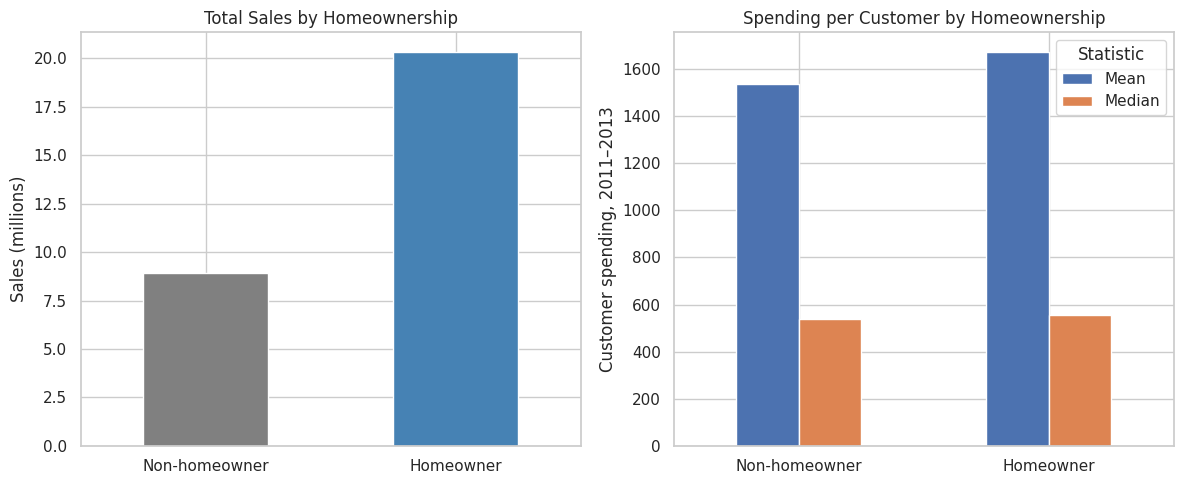

Customers  MeanSpendingPerCustomer  \
EnglishCountryRegionName Homeownership                                       
Australia                Homeowner           2262                  2559.20   
                         Non-homeowner       1281                  2531.36   
Canada                   Homeowner           1041                  1325.48   
                         Non-homeowner        504                  1160.69   
France                   Homeowner           1136                  1757.03   
                         Non-homeowner        610                  1051.53   
Germany                  Homeowner           1139                  1867.04   
                         Non-homeowner        581                  1315.79   
United Kingdom           Homeowner           1240                  1971.10   
                         Non-homeowner        634                  1487.60   
United States            Homeowner           5337                  1235.25   
                         Non-homeowner       2212                  1249.95   

                                        MedianSpendingPerCustomer  \
EnglishCountryRegionName Homeownership                              
Australia                Homeowner                        1938.47   
                         Non-homeowner                    2120.93   
Canada                   Homeowner                         256.24   
                         Non-homeowner                     188.42   
France                   Homeowner                         221.22   
                         Non-homeowner                      78.22   
Germany                  Homeowner                         603.49   
                         Non-homeowner                      98.96   
United Kingdom           Homeowner                         608.71   
                         Non-homeowner                     539.99   
United States            Homeowner                         130.46   
                         Non-homeowner                     146.67   

                                        MeanYearlyIncome  
EnglishCountryRegionName Homeownership                    
Australia                Homeowner              65468.61  
                         Non-homeowner          62310.69  
Canada                   Homeowner              59558.12  
                         Non-homeowner          52519.84  
France                   Homeowner              38565.14  
                         Non-homeowner          29868.85  
Germany                  Homeowner              43257.24  
                         Non-homeowner          41531.84  
United Kingdom           Homeowner              50040.32  
                         Non-homeowner          57034.70  
United States            Homeowner              64457.56  
                         Non-homeowner          61668.17

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

home_summary["TotalSales"].div(1_000_000).plot(
    kind="bar",
    ax=axes[0],
    color=["gray", "steelblue"]
)

axes[0].set_title("Total Sales by Homeownership")
axes[0].set_xlabel("")
axes[0].set_ylabel("Sales (millions)")
axes[0].tick_params(axis="x", rotation=0)

home_summary[
    ["MeanSpendingPerCustomer", "MedianSpendingPerCustomer"]
].rename(
    columns={
        "MeanSpendingPerCustomer": "Mean",
        "MedianSpendingPerCustomer": "Median"
    }
).plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Spending per Customer by Homeownership")
axes[1].set_xlabel("")
axes[1].set_ylabel("Customer spending, 2011–2013")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Statistic")

plt.tight_layout()
plt.show()

# Check whether the comparison changes within each country.
home_by_country = (
    customer_analysis.groupby(
        ["EnglishCountryRegionName", "Homeownership"]
    )
    .agg(
        Customers=("CustomerKey", "nunique"),
        MeanSpendingPerCustomer=("TotalSpending", "mean"),
        MedianSpendingPerCustomer=("TotalSpending", "median"),
        MeanYearlyIncome=("YearlyIncome", "mean")
    )
)

display(home_by_country)